In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


Import libraries

In [4]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
import matplotlib.pyplot as plt

Configurations

In [5]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
EPOCHS = 15
BASE_DIR = '/kaggle/input/chest-xray-pneumonia'

TRAIN_DIR = os.path.join(BASE_DIR,"chest_xray", 'train')
TEST_DIR = os.path.join(BASE_DIR,"chest_xray", 'test')
VAL_DIR = os.path.join(BASE_DIR,"chest_xray", 'val')

1. Data Preparation & Image Resizing

In [6]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

test_val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='binary'
)

val_generator = test_val_datagen.flow_from_directory(
    VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='binary'
)

test_generator = test_val_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='binary', shuffle=False
)

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


2. Data Balancing (Class Weights)

In [7]:
train_classes = train_generator.classes
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_classes),
    y=train_classes
)
class_weight_dict = dict(enumerate(class_weights))
print(f"Calculated Class Weights: {class_weight_dict}")

Calculated Class Weights: {0: np.float64(1.9448173005219984), 1: np.float64(0.6730322580645162)}


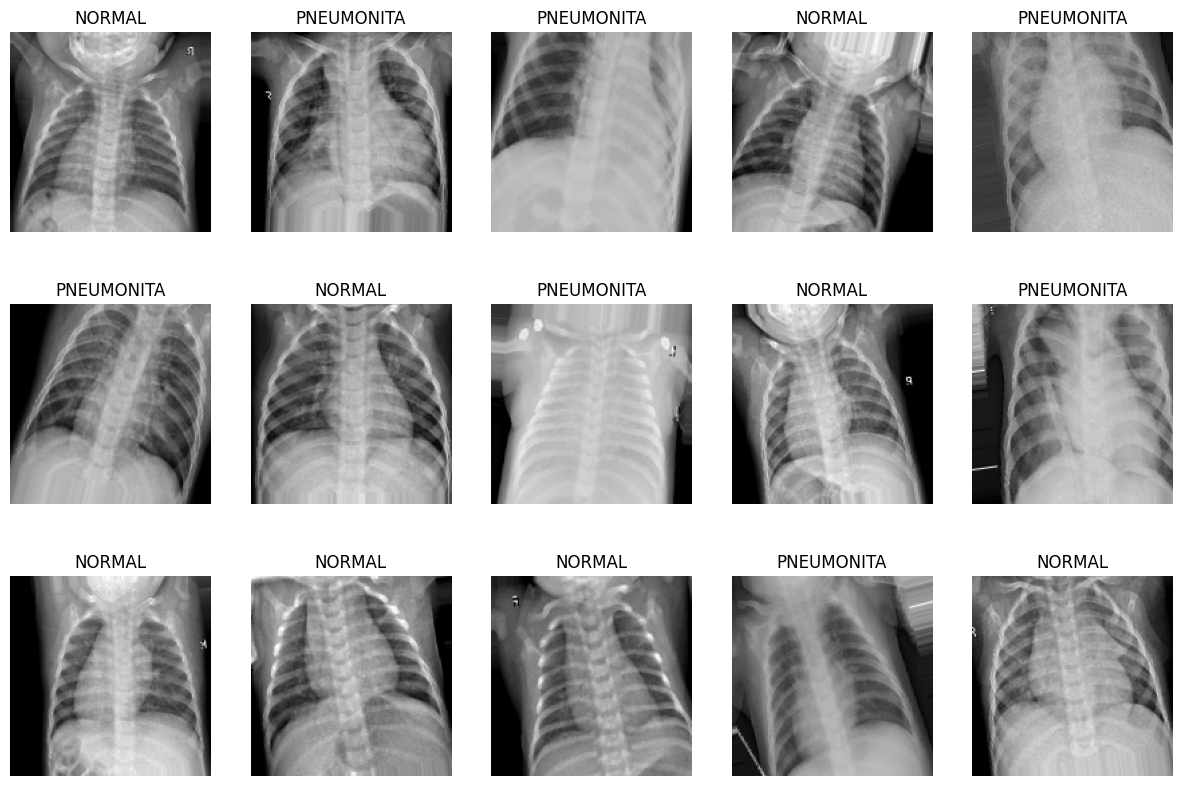

In [12]:
images,labels = next(train_generator)
plt.figure(figsize=(15,10))
for i in range(15):
  plt.subplot(3,5,i+1)
  plt.imshow(images[i])
  plt.title("PNEUMONITA" if labels[i]==1 else "NORMAL")
  plt.axis('off')
plt.show()

3. CNN Architecture & 4. Binary Crossentropy

In [13]:
model = models.Sequential([
    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Fully Connected Layer
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),

    # Output layer for Binary Classification
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

model.summary()

# --- Model Training ---
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    class_weight=class_weight_dict
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     2,367,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,460,865 (9.39 MB)

 Trainable params: 2,460,865 (9.39 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 295s 2s/step - accuracy: 0.7237 - auc: 0.8581 - loss: 0.4732 - val_accuracy: 0.7500 - val_auc: 0.9062 - val_loss: 0.5509
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 278s 2s/step - accuracy: 0.8762 - auc: 0.9501 - loss: 0.2808 - val_accuracy: 0.8125 - val_auc: 0.8828 - val_loss: 0.5084
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 280s 2s/step - accuracy: 0.8982 - auc: 0.9640 - loss: 0.2384 - val_accuracy: 0.8125 - val_auc: 0.9219 - val_loss: 0.4509
Epoch 4/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 279s 2s/step - accuracy: 0.9053 - auc: 0.9669 - loss: 0.2288 - val_accuracy: 0.7500 - val_auc: 0.8750 - val_loss: 0.7842
Epoch 5/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 275s 2s/step - accuracy: 0.9107 - auc: 0.9688 - loss: 0.2226 - val_accuracy: 0.8125 - val_auc: 0.9062 - val_loss: 0.6662
Epoch 6/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 281s 2s/step - accuracy: 0.9118 - auc: 0.9712 - loss: 0.2126 - val_accuracy: 0.8125 - val_auc: 0.9219 - val_loss: 0.4030
Epoch 7/15
163/163 ━━━━━━━━━━━━━━━

5. ROC-AUC Evaluation

In [14]:
test_labels = test_generator.classes
predictions = model.predict(test_generator, verbose=1).ravel()

# Calculate metrics
auc_score = roc_auc_score(test_labels, predictions)
fpr, tpr, thresholds = roc_curve(test_labels, predictions)

print(f"\nTest ROC-AUC Score: {auc_score:.4f}")
print("\nClassification Report:")
print(classification_report(test_labels, predictions > 0.5, target_names=test_generator.class_indices.keys()))

20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 669ms/step

Test ROC-AUC Score: 0.9377

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.93      0.62      0.74       234
   PNEUMONIA       0.81      0.97      0.88       390

    accuracy                           0.84       624
   macro avg       0.87      0.80      0.81       624
weighted avg       0.85      0.84      0.83       624



<Figure size 640x480 with 0 Axes>

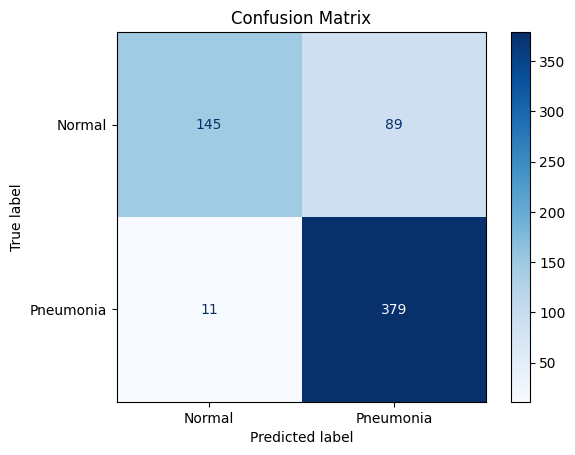

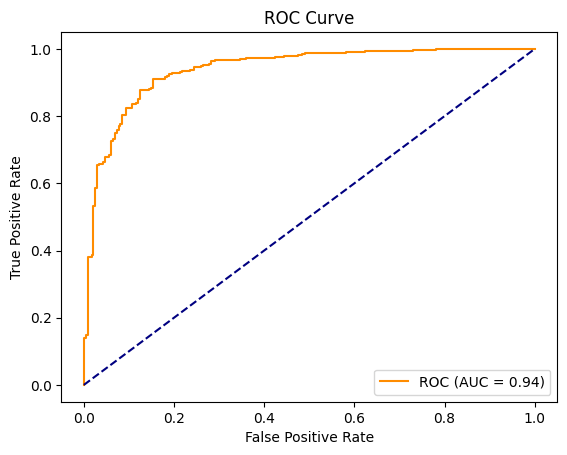

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import matplotlib.pyplot as plt

# 1. Plot Confusion Matrix
y_pred = (predictions > 0.5).astype(int)
cm = confusion_matrix(test_labels, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Pneumonia'])
plt.figure() # Use separate figure, no subplots
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

# 2. Plot ROC Curve
fpr, tpr, _ = roc_curve(test_labels, predictions)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', label=f'ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()